# 📚 03 - Using Help and Documentation

One of the most important skills in programming is knowing **how to get help**. Nobody memorizes every function. Good programmers know how to **investigate** unfamiliar code quickly. Jupyter/IPython have built-in tools for exactly that.

## ✅ Learning Goals
- Use `?`, `??`, and `help()` to read documentation and source code
- Use tab completion, hover, and `dir()` to discover names and methods
- Check an object's type and structure before looking anything up
- Read a function signature, including default values and the `/` and `*` markers
- Read an error message from the bottom up, and recognize the common error types
- Find, search, and trust the right **official** documentation
- Follow a step-by-step help workflow for unfamiliar code

> **The core habit:** use Jupyter's built-in tools to ask small questions quickly, then use the official documentation to understand the full answer.

## Setup
This notebook pokes at a few libraries you haven't studied yet, NumPy, Matplotlib, and Pandas. That's on purpose: these tools are **how** you explore a library you don't know. Following the habit from notebook 02, all the imports go in the first cell.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. Using `?` for Quick Help

Put a question mark **after** a name to see its documentation: the **signature** (what arguments it takes), a description, its parameters, and what it returns.

Use `?` when your question is: *"What does this do, and what arguments does it accept?"*

⚠️ The `?` must be the **last thing on the line**. `len?  # help for len` is a `SyntaxError`, so put comments on their own line.

In [2]:
# Show help for the built-in len() function
len?

In [3]:
# Show help for print()
print?

In [4]:
# Works on library functions too
np.arange?

### Searching with Wildcards
Don't know the exact name? Put `*` around part of it, and `?` lists every match:

In [5]:
np.*mean*?

✅ **Your Turn**:
1. Use `?` to check the documentation for `range` and `dict`.
2. Use `?` on `np.arange`. Which of its arguments are required, and which are optional?
3. Use a wildcard search to find every NumPy name containing `sort`.

In [6]:
# np.arange accepts required stop; start and step are optional.
range?
dict?
np.arange?
np.*sort*?

## 2. Using `??` for Source Code (if available)
`??` tries to show you the actual **source code**, not just the docstring. Use it when your question is: *"How does this work inside?"*

It won't work for everything. Many built-ins and much of NumPy are implemented in C (compiled code), not Python, so there's no Python source to show. You'll just get the docstring again.

In [7]:
# Try to view source code for sum(), a built-in written in C
sum??

Functions **you** write are always plain Python, so `??` shows their source:

In [8]:
def calculate_tax(price, rate=0.08):
    """Return the sales tax on a price."""
    return price * rate

calculate_tax??

💡 Notice that the text in triple quotes, the **docstring**, is what `?` displays. Write one for your own functions, and `?` will work on them too.

💡 **In VS Code**, right-click a name and choose **Go to Definition** (or press `F12`) to jump to its source code. This works for many library functions too.

✅ **Your Turn**:
1. Use `??` on `pd.read_csv` and see whether you get more detail than `?` gave you.
2. Write a small function of your own, with a docstring, and try both `?` and `??` on it.

In [9]:
# pd.read_csv is a Python wrapper around pandas' parser; inspect its source if available.
pd.read_csv??

def format_percent(value):
    """Format a decimal value as a percentage."""
    return f'{value:.1%}'

format_percent?
format_percent??
print(format_percent(0.125))

12.5%


## 3. The `help()` Function
`help()` is the plain built-in Python equivalent of `?` — it works the same way outside of Jupyter too, e.g. in a plain `.py` script run from the terminal.

In [10]:
help(len)

Help on built-in function len in module builtins:

len(obj, /)
    Return the number of items in a container.



In [11]:
import math
help(math.sqrt)

Help on built-in function sqrt in module math:

sqrt(x, /)
    Return the square root of x.



✅ **Your Turn**:
1. Use `help()` to explore `list.append` or `str.upper`.
2. Use `help(dict.get)` to learn what `.get()` does. Then create a dictionary and use `.get()` to look up a key that **doesn't** exist, without getting an error.

In [12]:
help(str.upper)
help(dict.get)

profile = {'name': 'Ada'}
print('missing major:', profile.get('major'))

Help on method_descriptor:

upper(self, /) unbound builtins.str method
    Return a copy of the string converted to uppercase.

Help on method_descriptor:

get(self, key, default=None, /) unbound builtins.dict method
    Return the value for key if key is in the dictionary, else default.

missing major: None


## 4. Tab Completion

Type the start of a name, or an object followed by a dot, and press `Tab` to see what's available:

```python
np.ar<TAB>        # arange, arccos, arcsin, array, ...
mylist = []
mylist.<TAB>      # append, clear, copy, count, ...
```

Tab completion helps you discover functions, avoid typos, and check spelling and capitalization.

### In VS Code
VS Code's **IntelliSense** goes further than classic Jupyter:
- Suggestions pop up **automatically** as you type. If they don't, press `Ctrl` + `Space`, and press `Tab` or `Enter` to accept one.
- **Hover** over any function name to see its documentation in a tooltip.
- Type a function name and `(`, and VS Code shows the **parameter hints**, with the argument you're currently typing in bold.

⚠️ Completion only knows about variables that **exist in the kernel**. Run the cell that creates `mylist` first, then use completion on `mylist.` in a later cell.

✅ **Your Turn**:
1. Create a dictionary, run the cell, and use tab completion to explore its methods.
2. Run `names = ['Ada', 'Grace', 'Katherine']`, then type `names.` and use completion to find the method that adds an item to the list.

In [13]:
# Tab itself must still be tried in VS Code; dir() shows the same method inventory in code.
profile = {'name': 'Ada', 'major': 'Math'}
print([name for name in dir(profile) if not name.startswith('_')])

names = ['Ada', 'Grace', 'Katherine']
print([name for name in dir(names) if not name.startswith('_')])
print('The list method that adds an item is append.')

['clear', 'copy', 'fromkeys', 'get', 'items', 'keys', 'pop', 'popitem', 'setdefault', 'update', 'values']
['append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']
The list method that adds an item is append.


## 5. Listing Everything with `dir()`
`dir(obj)` lists **every** name an object has. It's noisier than tab completion, but it returns a real Python list that you can filter:

In [14]:
scores = [82, 91, 76]
print(dir(scores))

['__add__', '__class__', '__class_getitem__', '__contains__', '__delattr__', '__delitem__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__imul__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__mul__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__reversed__', '__rmul__', '__setattr__', '__setitem__', '__sizeof__', '__str__', '__subclasshook__', 'append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']


The names wrapped in double underscores (`__len__`, `__init__`, ...) are Python's internal machinery. You don't need them yet. Filter them out to see the methods meant for you:

In [15]:
[name for name in dir(scores) if not name.startswith('_')]

['append',
 'clear',
 'copy',
 'count',
 'extend',
 'index',
 'insert',
 'pop',
 'remove',
 'reverse',
 'sort']

In [16]:
# Or search a whole library for a keyword
[name for name in dir(np) if 'mean' in name]

['mean', 'nanmean']

✅ **Your Turn**: Use `dir()` on a string (like `'hello'`) and filter out the underscore names. Find the method that changes text to UPPERCASE, and one other method you've never used. Try both.

In [17]:
text = 'prefix: hello world'
public_methods = [name for name in dir(text) if not name.startswith('_')]
print('upper' in public_methods, 'removeprefix' in public_methods)
print(text.upper())
print(text.removeprefix('prefix: '))
# removeprefix returns a new string only when the prefix is present.

True True
PREFIX: HELLO WORLD
hello world


## 6. Check the Type and Structure First
Before you look anything up, find out **what kind of object** you have. The right documentation depends on it. A list, a NumPy array, and a DataFrame all have different methods.

In [18]:
print(type([1, 2, 3]))
print(type(np.array([1, 2, 3])))
print(type(pd.DataFrame({'a': [1, 2]})))
print(type(plt))

<class 'list'>
<class 'numpy.ndarray'>
<class 'pandas.DataFrame'>
<class 'module'>


Arrays and DataFrames also tell you their **shape** (rows, columns) and the type of data they hold:

In [19]:
data = np.array([[1, 2, 3], [4, 5, 6]])

print('shape:', data.shape)   # 2 rows, 3 columns
print('dtype:', data.dtype)   # type of each element
print('ndim: ', data.ndim)    # number of dimensions

shape: (2, 3)
dtype: int64
ndim:  2


💡 **A quick debugging pattern.** When something behaves strangely, check `type(x)` first, then `len(x)` or `x.shape`, then look at a small piece with `x[:5]`. This often reveals the real problem, such as a string where you expected a number, or a list where you expected an array.

## 7. Reading Function Signatures
The **signature** at the top of `?` output tells you exactly what a function accepts. Here's `np.linspace`:

```text
linspace(start, stop, num=50, endpoint=True, ...)
```
- `start` and `stop` have no `=`, so they're **required**.
- `num=50` is **optional**, and it defaults to 50 if you leave it out.
- `endpoint=True` is optional, and defaults to `True`.

In [20]:
print(np.linspace(0, 10, num=5))
print(np.linspace(start=0, stop=10, num=5))   # same thing, more readable

[ 0.   2.5  5.   7.5 10. ]
[ 0.   2.5  5.   7.5 10. ]


### The `/` and `*` Markers
Some signatures contain a bare `/` or `*`. Run the cell below and look at the signature:

In [21]:
sorted?

```text
sorted(iterable, /, *, key=None, reverse=False)
```
- Arguments **before `/`** must be passed by **position**: `sorted(my_list)`, not `sorted(iterable=my_list)`.
- Arguments **after `*`** must be passed by **name**: `sorted(my_list, reverse=True)`, not `sorted(my_list, None, True)`.

You'll also see `*args` (any number of extra positional arguments) and `**kwargs` (any number of extra named arguments). Those were covered in Module 04.

## 8. Reading Error Messages
An error message (a **traceback**) can look scary, but there's a trick: **read the last line first**. It names the error type and says what went wrong. The lines above it show *where* it happened.

The cell below fails **on purpose**:

In [22]:
numbers = [1, 2, 3]
try:
    numbers.mean()
except AttributeError as error:
    # Preserve the intentional lesson error while allowing Run All to continue.
    print(type(error).__name__ + ':', error)

AttributeError: 'list' object has no attribute 'mean'


`AttributeError: 'list' object has no attribute 'mean'` means that a Python **list** doesn't have a `.mean()` method. (A NumPy array does.) Two fixes:

In [23]:
print(np.mean(numbers))          # use a function that accepts a list
print(np.array(numbers).mean())  # or convert to an array, which has .mean()

2.0
2.0


🔁 **Before you Restart & Run All:** Run All stops at the first error, so this deliberate error would keep every cell after it from running (see notebook 02). Once you've read the error, comment out the `numbers.mean()` line in the cell above (`Ctrl+/`, or `Cmd+/` on Mac). Do the same with any error you create on purpose in the Your Turn below.

### Common Error Types

| Error | Usually means... |
|---|---|
| `NameError` | A name isn't defined: a typo, or a cell you haven't run (see notebook 02) |
| `TypeError` | Wrong type for the operation, like `'5' + 5`, or the wrong number of arguments |
| `AttributeError` | That type of object doesn't have that method or attribute |
| `ValueError` | Right type, bad value, like `int('hello')` |
| `KeyError` | That key isn't in the dictionary (or column in the DataFrame) |
| `IndexError` | The position is past the end of the list |
| `ModuleNotFoundError` | The package isn't installed in this environment. Use `%pip install` (notebook 01) |
| `FileNotFoundError` | Wrong path or working directory |
| `SyntaxError` | Python can't even read the code: a missing `:`, `)`, or quote |

**Debugging questions to ask:**
1. What **type** is this object?
2. Is the name **spelled** correctly (including capitals)?
3. Does this method **belong** to this type of object?
4. What **arguments** does the function expect? (Check with `?`.)
5. Which **line number** and which **name** does the error point to?

✅ **Your Turn**: Run the code below. Read the error from the bottom up, and explain it in a comment. Then fix it so that `5` gets added to a **list** along with `12`.
```python
number = 12
number.append(5)
```

In [24]:
number = 12
try:
    number.append(5)
except AttributeError as error:
    # AttributeError: integers do not have the list method append().
    print(type(error).__name__, error)

numbers = [number]
numbers.append(5)
print(numbers)

AttributeError 'int' object has no attribute 'append'
[12, 5]


## 9. External Documentation

For the full story (every parameter, version-specific behavior, complete examples), go to the **official** documentation, maintained by the project itself:

| Tool | Official docs |
|---|---|
| Python | [docs.python.org/3](https://docs.python.org/3/) |
| Jupyter | [docs.jupyter.org](https://docs.jupyter.org/) |
| NumPy | [numpy.org/doc](https://numpy.org/doc/) |
| Matplotlib | [matplotlib.org/stable](https://matplotlib.org/stable/) |
| Pandas | [pandas.pydata.org/docs](https://pandas.pydata.org/docs/) |

Library docs usually have two main parts:
- **User Guide / Tutorials** explain concepts and workflows. Read these to **learn** a topic.
- **API Reference** lists every function, its parameters, and its return values. Use this to **look things up**.

Matplotlib also has a **Gallery** of complete example charts with their code. Find one close to what you want and adapt the smallest example.

### Match the Docs to Your Version
Libraries change between versions, and the docs have a version switcher. Check which versions you have:

In [25]:
print('NumPy:     ', np.__version__)
print('Pandas:    ', pd.__version__)
import matplotlib
print('Matplotlib:', matplotlib.__version__)

NumPy:      2.5.5
Pandas:     3.1.1
Matplotlib: 3.11.2


### Searching Effectively
Include the **library**, the **function**, and the **task**:
- ❌ `why does python hate me`
- ✅ `numpy mean ignore nan`
- ✅ `matplotlib scatter plot change marker size`
- ✅ `pandas read_csv site:pandas.pydata.org` (`site:` limits the search to the official docs)
- ✅ For an error, paste the **exact last line** in quotes: `"TypeError: can only concatenate str (not \"int\") to str"`

Tutorials, videos, Q&A sites, and AI assistants are great for **explanations**. Follow your course's policy on AI tools, and give them your exact code and error. But **verify** the important details against the official docs, because they can be outdated or confidently wrong.

✅ **Your Turn**: Look up the official Matplotlib documentation for `plt.bar`. In the cell below, write the **smallest** bar chart that works, using the docs' required arguments only. Then add a title and axis labels, one at a time, re-running after each change so you can see what each one does.

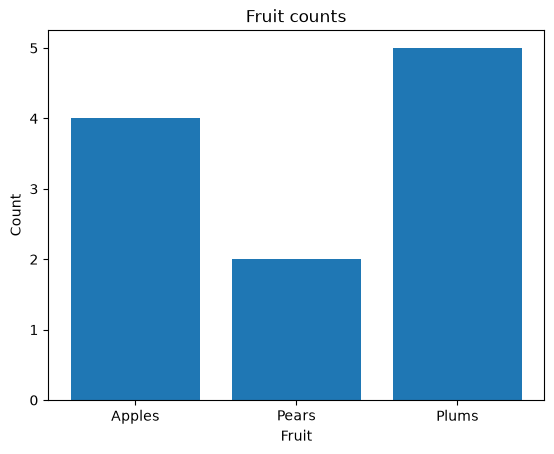

In [26]:
# Official pyplot.bar docs list x and height as required; width and other options default.
labels = ['Apples', 'Pears', 'Plums']
counts = [4, 2, 5]
plt.bar(labels, counts)
plt.title('Fruit counts')
plt.xlabel('Fruit')
plt.ylabel('Count')
plt.show()

## 10. Help for Magic Commands
The `?` trick works on magic commands too (see notebook 01). `%lsmagic` lists every magic, and `%magic` prints a long guide to all of them.

In [27]:
%timeit?

✅ **Your Turn**: Run `%lsmagic`, pick one magic you haven't used yet, and read its help with `?`. Describe in a comment what it does.

In [28]:
%lsmagic
%who?
# %who lists variables currently defined in the interactive namespace.
%who

calculate_tax	 counts	 data	 format_percent	 labels	 math	 matplotlib	 names	 np	 
number	 numbers	 pd	 plt	 profile	 public_methods	 scores	 text	 


## 11. A Practical Help Workflow
When you run into unfamiliar code, work through these steps in order. Most questions get answered by step 3 or 4:
1. **Identify the type** of the object: `type(x)`.
2. **Discover names** with `Tab`, `dir()`, or a wildcard `?` search.
3. **Read quick docs** with `?`, or hover in VS Code.
4. **Try a tiny example** in a new cell.
5. **Read the source** with `??` if you need to know how it works inside.
6. **Read the official docs** for the full details.
7. **Search the exact error message** if the example fails.

**Example:** *How do I find the median of an array?*

In [29]:
data = np.array([3, 5, 8, 10])

# Steps 2–3: search for a name, then read its docs
np.*median*?

In [30]:
# Step 4: try a tiny example
np.median(data)

np.float64(6.5)

✅ **Your Turn**: Use the workflow to find out how to generate **ten random integers from 1 through 6** (like dice rolls) with `np.random.randint`. Read the docs carefully: is the upper limit **included** or **excluded**? Check your answer by generating 1,000 rolls and printing the smallest and largest values you get.

In [31]:
np.random.seed(42)
rolls = np.random.randint(1, 7, size=1000)
# randint includes low and excludes high, so high=7 permits rolls from 1 through 6.
print('first ten:', rolls[:10])
print('minimum:', rolls.min(), 'maximum:', rolls.max())

first ten: [4 5 3 5 5 2 3 3 3 5]
minimum: 1 maximum: 6


---
### Summary

| Tool | Answers the question... | Works outside Jupyter? |
|---|---|---|
| `x?` | What does this do, and what arguments does it take? | No |
| `x??` | How is it written inside (if the source is in Python)? | No |
| `help(x)` | Same as `?`, printed as output | ✅ Yes |
| `Tab` / hover | What names and methods are available? What do they do? | Editor feature |
| `dir(x)` | List **every** name, as a list I can filter | ✅ Yes |
| `type(x)` | What kind of object is this? | ✅ Yes |
| Official docs | Everything: full parameters, examples, versions | — |

- Read signatures: no `=` means required, `name=value` shows the default, `/` means positional only, `*` means named only.
- Read errors **from the bottom up**: the last line has the error type and the reason.
- Search with the library + function + task, and verify what you find against the official docs for **your** version.

## 🏋️ Practice

### Practice 1 — Read Before You Ask (easy)
Before looking anything up online, use `?` to answer: does `str.split()` split on *every* whitespace character by default, or just spaces? Write your answer as a comment.

In [32]:
# With no separator, str.split() splits runs of all whitespace, not only spaces.
example = 'one\ttwo\nthree  four'
print(example.split())

['one', 'two', 'three', 'four']


### Practice 2 — Compare Two Functions (medium)
Use `help()` on both `sorted()` and `list.sort()`. Write a one-line comment explaining the key difference between them (hint: what each one returns).

In [33]:
# sorted() returns a new sorted list; list.sort() changes the list in place and returns None.
values = [3, 1, 2]
sorted_copy = sorted(values)
print(sorted_copy, values)
print(values.sort(), values)

[1, 2, 3] [3, 1, 2]
None [1, 2, 3]


### Practice 3 — Find It Yourself (harder)
Without searching online, use `?`, tab completion, and `dir()` on a string to find a string method you haven't used yet in this course. Try it out and explain what it does in a comment.

In [34]:
# dir() helps discover names; actual Tab completion remains a VS Code action to try.
str.removeprefix?
text = 'prefix: foundations'
print([name for name in dir(text) if not name.startswith('_') and 'prefix' in name])
print(text.removeprefix('prefix: '))  # Remove a known prefix, leaving the original unchanged.

['removeprefix']
foundations


### Practice 4 — Pick the Right Tool (medium)
In the Markdown cell below, describe in your own words when you would use each of these: `?`, `??`, `help()`, `Tab`, and `dir()`. For each one, give a situation where it's the **best** choice.

**Draft answer for Inuka to review and rewrite in his own words:**

- Use `?` for a quick signature and docstring, such as checking a function's arguments.
- Use `??` when the implementation might be available as Python source.
- Use `help()` when working in a plain Python terminal or script, outside Jupyter.
- Use Tab when I am typing in the editor and want completion suggestions immediately.
- Use `dir()` when I need a filterable list of every attribute or method on an object.

The literal Tab-completion exercises still need to be tried in VS Code.

## 🔥 Challenge (Optional) — Explore a Library You've Never Used
Using **only** the built-in tools from this notebook (`?`, `??`, `help()`, `Tab`, `dir()`, wildcard search, and no web searching), explore Python's `datetime` and `statistics` modules:
1. `import datetime` and find out how to get **today's date**. Then find how to get the **day of the week** from it. (Is Monday 0 or 1? The docs will tell you.)
2. `import statistics` and find a function that returns the **most common** value in a list. Test it on `[3, 1, 3, 2, 3, 1]`.
3. Find a `statistics` function you didn't know existed, read its docs, and demonstrate it.

In comments, record **which tool** answered each question.

In [35]:
import datetime
import statistics

datetime.date.today?
today = datetime.date.today()
today.weekday?
print('today:', today, 'weekday:', today.weekday())

statistics.mode?
values = [3, 1, 3, 2, 3, 1]
print('mode:', statistics.mode(values))

statistics.fmean?
print('fmean:', statistics.fmean(values))

today: 2026-11-23 weekday: 0
mode: 3
fmean: 2.1666666666666665
